# Experiment 4 — EDAIN (multivariate, target `num_jobs`)

Backbones: **LSTM + GRU**.

Derived from `lstm-edain.ipynb` in the KSAK repo. The normalization layer, the model,
the split, the sliding-window tuning and the Iverson metrics are unchanged.

Changes from the repo notebook:

- a **CONFIG cell** at the top (dataset, feature mode, target, seed, epochs, windows)
- a **`FEATURE_MODE` switch** — the EDAIN notebook hardcoded all 7 columns and
  could only run multivariate
- **GRU kept**, as in the repo notebook (`MODEL_TYPES = ['LSTM', 'GRU']`)
- seeding was already there (`SEED = 42`) and is unchanged
- appends one row per backbone to `results.csv`

In [ ]:
# ============================================================
# EXPERIMENT 4 — EDAIN | multivariate | target = num_jobs
# Backbones: LSTM + GRU
# ============================================================
# Switch DATASET between '09' and '25' and re-run the notebook.
# The .swf files sit in this same folder.
DATASET = '09'                     # '09' | '25'

DATA_FILES = {
    '09': '09-SDSC-SP2-1998-4.2-cln.swf',
    '25': '25-LLNL-uBGL-2006-2.swf',
}
DATASET_PATH = DATA_FILES[DATASET]

FEATURE_MODE = 'multivariate'
TARGET_COL   = 'num_jobs'

RUN_NAME    = f'04-edain-multi-numjobs-log{DATASET}'
RESULTS_CSV = 'results.csv'

SLICE_MINUTES     = 15
WINDOW_CANDIDATES = [30, 60, 90, 120]
BATCH_SIZE        = 32
EPOCHS            = 50
SEED              = 42

# --- reproducibility -----------------------------------------------------
import os, random
import numpy as np
import tensorflow as tf

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'Run: {RUN_NAME}')
print(f'Data: {DATASET_PATH}')
print(f'Feature mode: {FEATURE_MODE} | Target: {TARGET_COL} | Seed: {SEED}')


Run: 04-edain-multi-numjobs-log25
Data: 25-LLNL-uBGL-2006-2.swf
Feature mode: multivariate | Target: num_jobs | Seed: 42


## 1. Setup
Imports, global constants, and random seeds.

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tabulate import tabulate
from tensorflow.keras.layers import Dense, Dropout, GRU, LSTM
from tensorflow.keras.optimizers import Adam

sns.set_style('whitegrid')
plt.style.use('fivethirtyeight')
%matplotlib inline

In [3]:
# DATASET_PATH, SLICE_MINUTES, WINDOW_CANDIDATES, BATCH_SIZE, EPOCHS and SEED
# come from the CONFIG cell above.
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.85

MODEL_TYPES = ['LSTM', 'GRU']
BASE_LR = 1e-3
EDAIN_LR_SCALES = {'outlier': 100.0, 'shift': 0.01, 'scale': 0.01, 'power': 10.0}

# Feature mode switch: 'univariate' uses only the target; 'multivariate' all covariates.
MULTIVARIATE_FEATURE_COLS = [
    'num_jobs',
    'total_allocated_proc',
    'std_allocated_proc',
    'total_run_time',
    'std_run_time',
    'avg_allocated_proc',
    'avg_run_time',
]

if FEATURE_MODE == 'univariate':
    FEATURE_COLS = [TARGET_COL]
elif FEATURE_MODE == 'multivariate':
    FEATURE_COLS = list(MULTIVARIATE_FEATURE_COLS)
else:
    raise ValueError("FEATURE_MODE must be 'univariate' or 'multivariate'")

print('Feature mode:', FEATURE_MODE)
print('Features:', FEATURE_COLS)


Feature mode: multivariate
Features: ['num_jobs', 'total_allocated_proc', 'std_allocated_proc', 'total_run_time', 'std_run_time', 'avg_allocated_proc', 'avg_run_time']


In [4]:
tf.keras.utils.set_random_seed(SEED)

## 2. Data Preparation
Load the Parquet trace, convert `submit_time` to seconds since the first job, and aggregate jobs into fixed time slices.

In [5]:
# Standard Workload Format columns (same list as last sprint's notebook).
SWF_LABELS = (
    "job_id", "submit_time", "wait_time", "run_time", "allocated_proc", "cpu_time",
    "used_mem", "requested_proc", "requested_time", "requested_mem", "status",
    "user_id", "group_id", "executable_id", "queue_id", "partition_id",
    "preceding_job_id", "think_time",
)

def preprocess_data(path, slice_minutes):
    jobs = pd.read_csv(path, header=None, names=SWF_LABELS, delimiter=r"\s+",
                       comment=";", usecols=['submit_time', 'run_time', 'allocated_proc'])
    jobs = jobs.astype({'run_time': 'float64', 'allocated_proc': 'float64'})

    jobs['submit_time'] = jobs['submit_time'] - jobs['submit_time'].min()

    jobs = jobs[jobs['run_time'] > 0].copy()
    jobs['slice'] = (jobs['submit_time'] // (slice_minutes * 60)).astype('int64')

    data_agg = jobs.groupby('slice').agg(
        num_jobs=('run_time', 'size'),
        total_run_time=('run_time', 'sum'),
        std_run_time=('run_time', 'std'),
        total_allocated_proc=('allocated_proc', 'sum'),
        std_allocated_proc=('allocated_proc', 'std'),
    )
    data_agg['avg_allocated_proc'] = data_agg['total_allocated_proc'] / data_agg['num_jobs']
    data_agg['avg_run_time'] = data_agg['total_run_time'] / data_agg['num_jobs']

    full_range = np.arange(data_agg.index.min(), data_agg.index.max() + 1)
    data_agg = data_agg.reindex(full_range, fill_value=0).fillna(0)

    return data_agg.reset_index(drop=True)[FEATURE_COLS]


df = preprocess_data(DATASET_PATH, SLICE_MINUTES)
df

,num_jobs,total_allocated_proc,std_allocated_proc,total_run_time,std_run_time,avg_allocated_proc,avg_run_time
0,2,512.0,0.0,14393.0,6.363961,256.0,7196.5
1,0,0.0,0.0,0.0,0.000000,0.0,0.0
2,0,0.0,0.0,0.0,0.000000,0.0,0.0
3,1,1024.0,0.0,3355.0,0.000000,1024.0,3355.0
4,0,0.0,0.0,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...
21345,0,0.0,0.0,0.0,0.000000,0.0,0.0
21346,1,1024.0,0.0,2892.0,0.000000,1024.0,2892.0
21347,0,0.0,0.0,0.0,0.000000,0.0,0.0
21348,0,0.0,0.0,0.0,0.000000,0.0,0.0


## 3. Splitting and Scaling
Chronological 70/15/15 split; a z-score scaler fitted on the training rows only precedes EDAIN, as the repository recommends for the global-aware layer.

In [6]:
dataset = df[FEATURE_COLS].to_numpy(dtype=np.float64)
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

train_end = int(np.ceil(len(dataset) * TRAIN_FRACTION))
val_end = int(np.ceil(len(dataset) * VALIDATION_FRACTION))

print(f"Training: {train_end} | Validation: {val_end - train_end} | Test: {len(dataset) - val_end}")
print("Features:", FEATURE_COLS)
print("Target:", TARGET_COL, "| index:", target_idx)

Training: 14945 | Validation: 3203 | Test: 3202
Features: ['num_jobs', 'total_allocated_proc', 'std_allocated_proc', 'total_run_time', 'std_run_time', 'avg_allocated_proc', 'avg_run_time']
Target: num_jobs | index: 0


In [7]:
scaler = StandardScaler().fit(dataset[:train_end])
scaled_data = scaler.transform(dataset).astype(np.float32)

target_mean = float(scaler.mean_[target_idx])
target_std = float(scaler.scale_[target_idx])

In [8]:
def create_sequences(start_idx, end_idx, window_size):
    x = np.stack([scaled_data[i - window_size:i] for i in range(start_idx + window_size, end_idx)])
    y_scaled = scaled_data[start_idx + window_size:end_idx, target_idx:target_idx + 1]
    y_raw = dataset[start_idx + window_size:end_idx, target_idx:target_idx + 1]
    return x.astype(np.float32), y_scaled, y_raw

## 4. Error Metrics
Iverson-bracket metrics that only score time slices where the actual value is non-zero.

In [9]:
def flatten(array):
    return np.asarray(array, dtype=float).reshape(-1)


def iverson_mse(actual, prediction):
    actual, prediction = flatten(actual), flatten(prediction)
    iverson = actual != 0.0

    return ((prediction - actual) ** 2 * iverson).sum() / iverson.sum()


def iverson_mae(actual, prediction):
    actual, prediction = flatten(actual), flatten(prediction)
    iverson = actual != 0.0

    return (np.abs(prediction - actual) * iverson).sum() / iverson.sum()


def iverson_rmse(actual, prediction):
    return np.sqrt(iverson_mse(actual, prediction))

## 5. EDAIN Layer
Keras translation of the global-aware EDAIN layer from [marcusGH/edain_paper](https://github.com/marcusGH/edain_paper), applying outlier removal, shift, scale, and a Yeo-Johnson power transform with learnable parameters.

In [10]:
class AdaptiveOutlierRemoval(tf.keras.layers.Layer):
    def __init__(self, residual_connection=True, mode='exp', min_beta=1.0, init_sigma=0.1, **kwargs):
        super().__init__(**kwargs)
        if mode not in ('exp', 'softplus'):
            raise ValueError(f"Unknown outlier removal mode: {mode}")
        self.residual_connection = residual_connection
        self.mode = mode
        self.min_beta = min_beta
        self.init_sigma = init_sigma

    def build(self, input_shape):
        window_size, dim = input_shape[1], input_shape[-1]
        self.log_cutoff = self.add_weight(
            name='log_cutoff', shape=(dim,),
            initializer=tf.keras.initializers.RandomNormal(1.0, self.init_sigma))
        if self.residual_connection:
            self.alpha = self.add_weight(
                name='alpha', shape=(dim,),
                initializer=tf.keras.initializers.RandomNormal(0.0, self.init_sigma))
        self.running_mean = self.add_weight(
            name='running_mean', shape=(window_size, dim), initializer='zeros', trainable=False)
        self.running_n = self.add_weight(
            name='running_n', shape=(), initializer='zeros', trainable=False)

    def call(self, x, training=False):
        mean = tf.convert_to_tensor(self.running_mean)
        if training:
            batch = tf.cast(tf.shape(x)[0], x.dtype)
            total = self.running_n + batch
            mean = (mean * self.running_n + tf.reduce_sum(tf.stop_gradient(x), axis=0)) / total
            self.running_mean.assign(mean)
            self.running_n.assign(total)

        if self.mode == 'exp':
            beta = self.min_beta + tf.exp(self.log_cutoff)
        else:
            beta = self.min_beta + tf.nn.softplus(self.log_cutoff)

        x_tanh = beta * tf.tanh((x - mean) / beta) + mean
        if self.residual_connection:
            gate = tf.sigmoid(self.alpha)
            return (1.0 - gate) * x + gate * x_tanh
        return x_tanh


class AdaptiveShift(tf.keras.layers.Layer):
    def __init__(self, init_sigma=0.1, **kwargs):
        super().__init__(**kwargs)
        self.init_sigma = init_sigma

    def build(self, input_shape):
        self.shift = self.add_weight(
            name='shift', shape=(input_shape[-1],),
            initializer=tf.keras.initializers.RandomNormal(0.0, self.init_sigma))

    def call(self, x, training=False):
        return x - self.shift


class AdaptiveScale(tf.keras.layers.Layer):
    def __init__(self, init_sigma=0.1, **kwargs):
        super().__init__(**kwargs)
        self.init_sigma = init_sigma

    def build(self, input_shape):
        self.log_scale = self.add_weight(
            name='log_scale', shape=(input_shape[-1],),
            initializer=tf.keras.initializers.RandomNormal(0.0, self.init_sigma))

    def call(self, x, training=False):
        return x * tf.exp(-self.log_scale)


class AdaptivePowerTransform(tf.keras.layers.Layer):
    def __init__(self, init_sigma=0.1, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.init_sigma = init_sigma
        self.eps = eps

    def build(self, input_shape):
        self.lambd = self.add_weight(
            name='lambd', shape=(input_shape[-1],),
            initializer=tf.keras.initializers.RandomNormal(1.0, self.init_sigma))

    def call(self, x, training=False):
        lam = tf.convert_to_tensor(self.lambd)
        abs_x = tf.abs(x)
        is_l0 = tf.abs(lam) < self.eps
        is_l2 = tf.abs(lam - 2.0) < self.eps
        safe_l0 = tf.where(is_l0, tf.ones_like(lam), lam)
        safe_l2 = tf.where(is_l2, tf.ones_like(lam), lam - 2.0)

        positive = tf.where(
            is_l0, tf.math.log1p(abs_x), (tf.pow(abs_x + 1.0, safe_l0) - 1.0) / safe_l0)
        negative = tf.where(
            is_l2, -tf.math.log1p(abs_x), (tf.pow(abs_x + 1.0, -safe_l2) - 1.0) / safe_l2)

        return tf.where(x >= 0.0, positive, negative)


class EDAINLayer(tf.keras.layers.Layer):
    def __init__(self, residual_connection=True, outlier_mode='exp', init_sigma=0.1, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.outlier_removal = AdaptiveOutlierRemoval(residual_connection, outlier_mode, init_sigma=init_sigma)
        self.shift = AdaptiveShift(init_sigma)
        self.scale = AdaptiveScale(init_sigma)
        self.power_transform = AdaptivePowerTransform(init_sigma, eps)

    def call(self, x, training=False):
        x = self.outlier_removal(x, training=training)
        x = self.shift(x, training=training)
        x = self.scale(x, training=training)
        return self.power_transform(x, training=training)

    def sublayers(self):
        return {
            'outlier': self.outlier_removal,
            'shift': self.shift,
            'scale': self.scale,
            'power': self.power_transform,
        }

## 6. Forecasting Model
EDAIN feeds an LSTM or GRU backbone, and each EDAIN sublayer is trained with its own learning-rate modifier as in the repository's example.

In [11]:
def clone_optimizer_with_lr(optimizer, learning_rate):
    config = optimizer.get_config()
    config['learning_rate'] = learning_rate
    return optimizer.__class__.from_config(config)


class EDAINForecastModel(tf.keras.Model):
    def __init__(self, edain_layer, backbone_layers, **kwargs):
        super().__init__(**kwargs)
        self.edain = edain_layer
        self.backbone_layers = backbone_layers
        self.loss_tracker = tf.keras.metrics.Mean(name='loss')

    def call(self, inputs, training=False):
        x = self.edain(inputs, training=training)
        for layer in self.backbone_layers:
            x = layer(x, training=training)
        return x

    def compile(self, optimizer, base_lr, lr_scales, **kwargs):
        super().compile(optimizer=optimizer, **kwargs)
        self.loss_fn = tf.keras.losses.MeanSquaredError()
        self.edain_optimizers = {
            name: clone_optimizer_with_lr(optimizer, base_lr * scale)
            for name, scale in lr_scales.items()
        }

    @property
    def metrics(self):
        return [self.loss_tracker]

    @staticmethod
    def apply_group(optimizer, grads, variables):
        pairs = [(g, v) for g, v in zip(grads, variables) if g is not None]
        if pairs:
            optimizer.apply_gradients(pairs)

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            pred = self(x, training=True)
            loss = self.loss_fn(y, pred)
            if self.losses:
                loss += tf.add_n(self.losses)

        variables = self.trainable_variables
        grads = dict(zip((id(v) for v in variables), tape.gradient(loss, variables)))

        edain_ids = set()
        for name, sublayer in self.edain.sublayers().items():
            group = list(sublayer.trainable_variables)
            edain_ids.update(id(v) for v in group)
            self.apply_group(self.edain_optimizers[name], [grads[id(v)] for v in group], group)

        main = [v for v in variables if id(v) not in edain_ids]
        self.apply_group(self.optimizer, [grads[id(v)] for v in main], main)

        self.loss_tracker.update_state(loss)
        return {'loss': self.loss_tracker.result()}

    def test_step(self, data):
        x, y = data
        pred = self(x, training=False)
        loss = self.loss_fn(y, pred)
        self.loss_tracker.update_state(loss)
        return {'loss': self.loss_tracker.result()}

In [12]:
def build_model(model_type, window_size):
    recurrent = {'LSTM': LSTM, 'GRU': GRU}[model_type]
    backbone_layers = [
        recurrent(64, return_sequences=True),
        Dropout(0.2),
        recurrent(32, return_sequences=False),
        Dropout(0.2),
        Dense(16, activation='relu'),
        Dense(1),
    ]

    model = EDAINForecastModel(EDAINLayer(name='EDAIN'), backbone_layers, name=f'EDAIN_{model_type}')
    model.compile(optimizer=Adam(learning_rate=BASE_LR), base_lr=BASE_LR, lr_scales=EDAIN_LR_SCALES)
    model(tf.zeros((1, window_size, n_features)), training=False)
    return model


def predict_original_scale(model, x):
    return model.predict(x, verbose=0) * target_std + target_mean

## 7. Sliding Window Tuning
Each candidate lookback window is trained on the training split and scored by validation Iverson RMSE; the best window is kept per model.

In [13]:
def tune_window(model_type):
    results = []
    for window_size in WINDOW_CANDIDATES:
        x_train, y_train, _ = create_sequences(0, train_end, window_size)
        x_val, y_val, y_val_raw = create_sequences(train_end, val_end, window_size)

        model = build_model(model_type, window_size)
        model.fit(x_train, y_train, validation_data=(x_val, y_val),
                  batch_size=BATCH_SIZE, epochs=EPOCHS, verbose=0)

        val_rmse = iverson_rmse(y_val_raw, predict_original_scale(model, x_val))
        results.append((window_size, val_rmse))
        print(f'{model_type} | window={window_size:3d} -> validation Iverson RMSE: {val_rmse:.4f}')
        tf.keras.backend.clear_session()

    best_window = min(results, key=lambda r: r[1])[0]
    print(f'Selected window for {model_type}: {best_window}')
    return results, best_window


def plot_window_tuning(model_type, results, best_window):
    window_df = pd.DataFrame(results, columns=['Window Size', 'Validation Iverson RMSE'])
    best_rmse = window_df.loc[window_df['Window Size'] == best_window, 'Validation Iverson RMSE'].item()

    plt.figure(figsize=(8, 4))
    plt.bar(window_df['Window Size'].astype(str), window_df['Validation Iverson RMSE'], color='steelblue')
    plt.axhline(best_rmse, color='crimson', linestyle='--', label=f'Best: {best_window}')
    plt.title(f'Sliding Window Tuning - {model_type}')
    plt.xlabel('Lookback Window (slices)')
    plt.ylabel('Validation Iverson RMSE')
    plt.legend()
    plt.tight_layout()
    plt.show()


tuning = {}

### LSTM

LSTM | window= 30 -> validation Iverson RMSE: 1.5582

LSTM | window= 60 -> validation Iverson RMSE: 1.5730
LSTM | window= 90 -> validation Iverson RMSE: 1.6172
LSTM | window=120 -> validation Iverson RMSE: 1.6635
Selected window for LSTM: 30


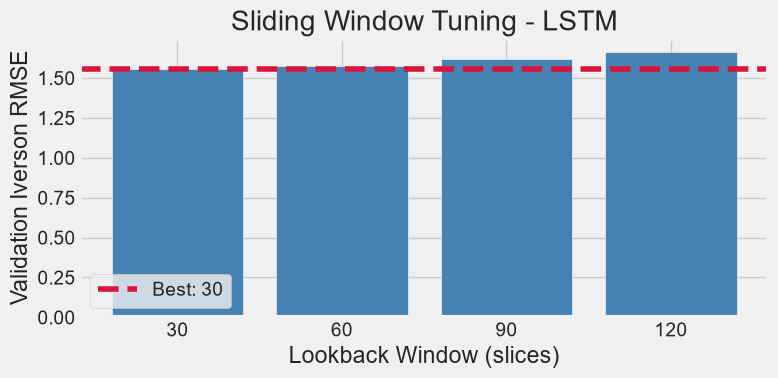

In [14]:
tuning['LSTM'] = tune_window('LSTM')
plot_window_tuning('LSTM', *tuning['LSTM'])

### GRU

GRU | window= 30 -> validation Iverson RMSE: 1.5013
GRU | window= 60 -> validation Iverson RMSE: 1.5449
GRU | window= 90 -> validation Iverson RMSE: 1.4531
GRU | window=120 -> validation Iverson RMSE: 1.5619
Selected window for GRU: 90


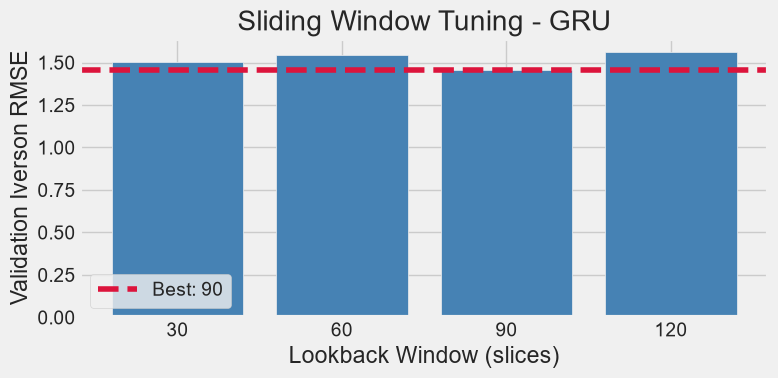

In [15]:
tuning['GRU'] = tune_window('GRU')
plot_window_tuning('GRU', *tuning['GRU'])

## 8. Training
Each model is trained with its selected window; the loss is the MSE on the standardized target.

In [16]:
def train_model(model_type):
    window_size = tuning[model_type][1]
    x_train, y_train, _ = create_sequences(0, train_end, window_size)
    x_val, y_val, _ = create_sequences(train_end, val_end, window_size)
    x_test, _, y_test_raw = create_sequences(val_end, len(dataset), window_size)

    model = build_model(model_type, window_size)
    history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                        batch_size=BATCH_SIZE, epochs=EPOCHS, verbose=1)
    return model, history, (x_test, y_test_raw)


models, histories, test_sets = {}, {}, {}

### LSTM

In [17]:
models['LSTM'], histories['LSTM'], test_sets['LSTM'] = train_model('LSTM')

Epoch 1/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 0.5016 - val_loss: 0.2370
Epoch 2/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.3342 - val_loss: 0.2218
Epoch 3/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.3070 - val_loss: 0.2238
Epoch 4/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2958 - val_loss: 0.2201
Epoch 5/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 0.2839 - val_loss: 0.2221
Epoch 6/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2868 - val_loss: 0.2202
Epoch 7/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.2760 - val_loss: 0.2244
Epoch 8/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2650 - val_loss: 0.2159
Epoch 9/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2605 - val_loss: 0.2330
Epoch 10/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2446 - val_loss: 0.2277
Epoch 11/50
467/467 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.2448 - val_loss: 0.2285
Epoch 12/50
467/467 ━━━━━━━━━━━━

### GRU

In [18]:
models['GRU'], histories['GRU'], test_sets['GRU'] = train_model('GRU')

Epoch 1/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 34s 62ms/step - loss: 0.4924 - val_loss: 0.2643
Epoch 2/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - loss: 0.3300 - val_loss: 0.2379
Epoch 3/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - loss: 0.3039 - val_loss: 0.2432
Epoch 4/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - loss: 0.2973 - val_loss: 0.2525
Epoch 5/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 28s 61ms/step - loss: 0.2881 - val_loss: 0.2427
Epoch 6/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 28s 61ms/step - loss: 0.2802 - val_loss: 0.2304
Epoch 7/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 61ms/step - loss: 0.2703 - val_loss: 0.2438
Epoch 8/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 63ms/step - loss: 0.2631 - val_loss: 0.2317
Epoch 9/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - loss: 0.2573 - val_loss: 0.2304
Epoch 10/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - loss: 0.2536 - val_loss: 0.2362
Epoch 11/50
465/465 ━━━━━━━━━━━━━━━━━━━━ 30s 65ms/step - loss: 0.2398 - val_loss: 0.2302
Epoch 12/50
465/465 ━━━━━━━━━━

## 9. Evaluation
Test-set predictions are mapped back to the original scale and scored with the Iverson metrics.

In [19]:
predictions, metrics_values = {}, {}
for model_type in MODEL_TYPES:
    x_test, y_test_raw = test_sets[model_type]
    predictions[model_type] = predict_original_scale(models[model_type], x_test)
    metrics_values[model_type] = {
        'I-MSE': iverson_mse(y_test_raw, predictions[model_type]),
        'I-RMSE': iverson_rmse(y_test_raw, predictions[model_type]),
        'I-MAE': iverson_mae(y_test_raw, predictions[model_type]),
    }

print(tabulate(
    [[name, f"{m['I-MSE']:.4f}", f"{m['I-RMSE']:.4f}", f"{m['I-MAE']:.4f}"] for name, m in metrics_values.items()],
    headers=['Model', 'I-MSE', 'I-RMSE', 'I-MAE'],
    tablefmt='pretty',
))

+-------+--------+--------+--------+
| Model | I-MSE  | I-RMSE | I-MAE  |
+-------+--------+--------+--------+
| LSTM  | 1.3210 | 1.1493 | 0.7990 |
|  GRU  | 1.2457 | 1.1161 | 0.7646 |
+-------+--------+--------+--------+


## 10. Visualizations
Prediction overlays and training curves for both models.

### Ground Truth vs Prediction

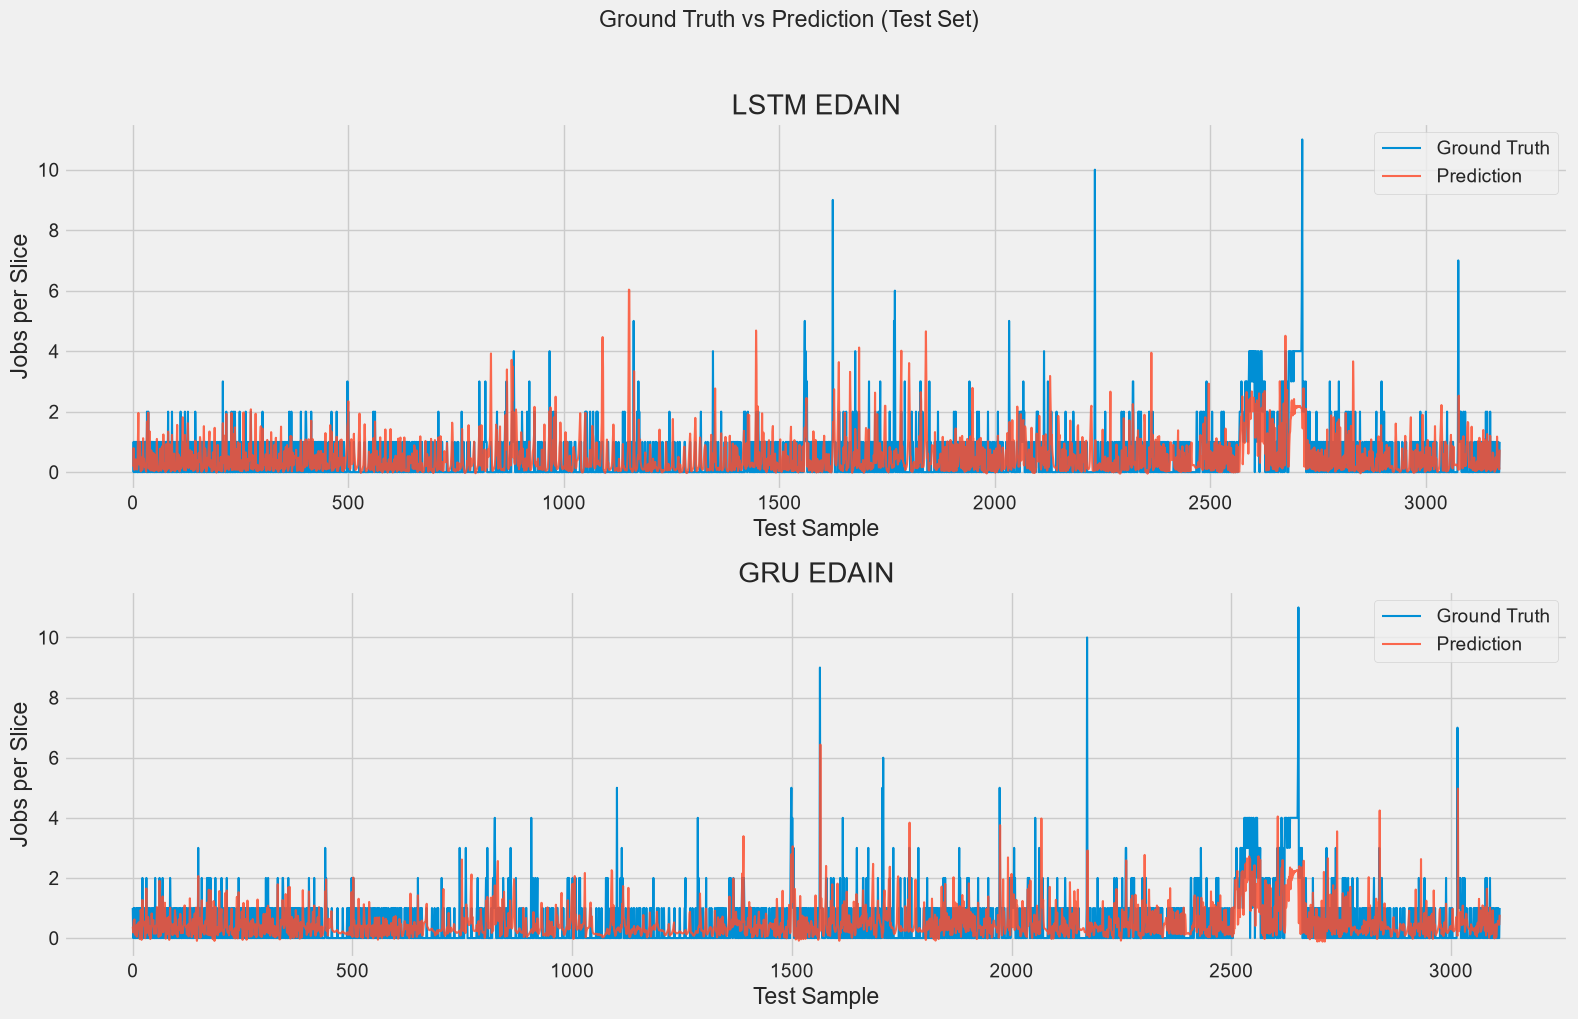

In [20]:
fig, axes = plt.subplots(len(MODEL_TYPES), 1, figsize=(16, 10))
for ax, model_type in zip(axes, MODEL_TYPES):
    ax.plot(test_sets[model_type][1], label='Ground Truth', linewidth=1.5)
    ax.plot(predictions[model_type], label='Prediction', linewidth=1.5, alpha=0.85)
    ax.set_title(f'{model_type} EDAIN')
    ax.set_xlabel('Test Sample')
    ax.set_ylabel('Jobs per Slice')
    ax.legend()

plt.suptitle('Ground Truth vs Prediction (Test Set)', y=1.02)
plt.tight_layout()
plt.show()

### Loss Curves

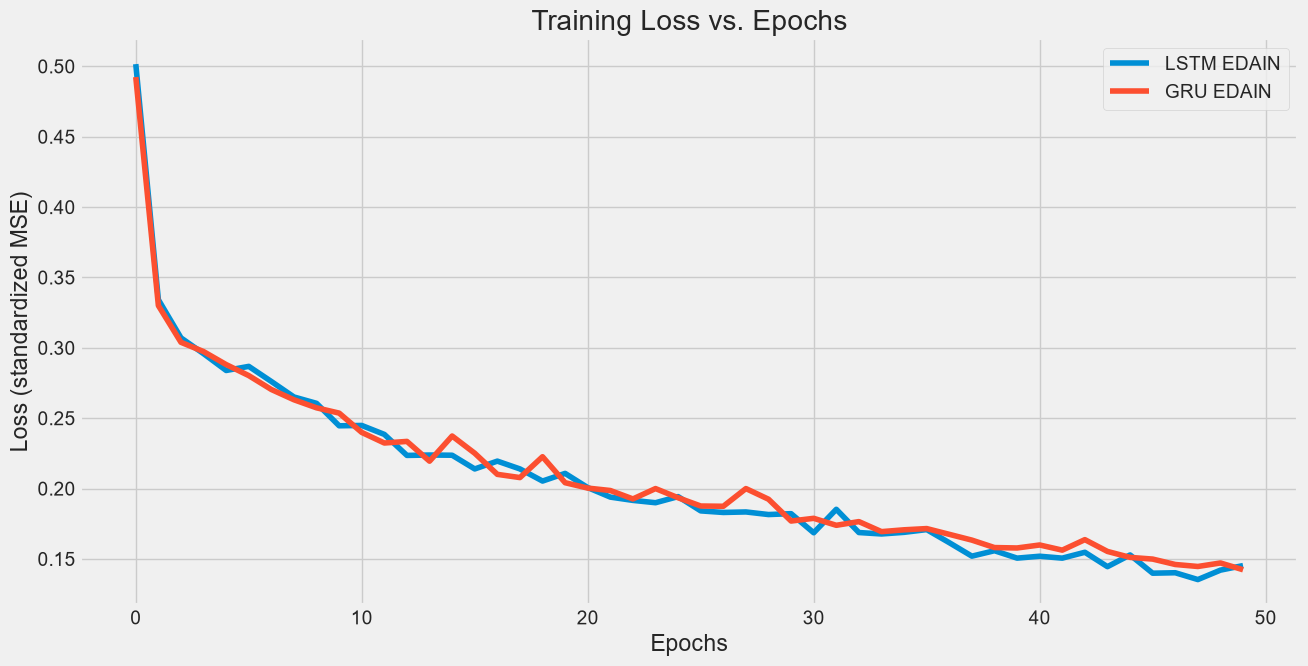

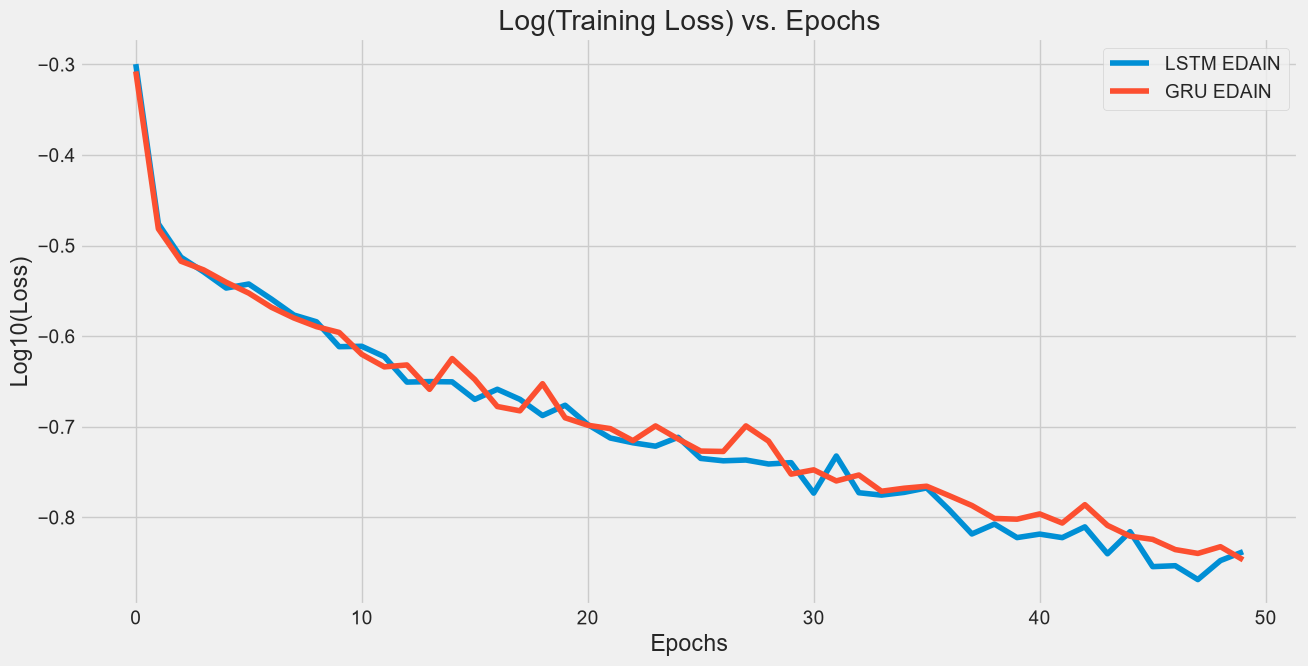

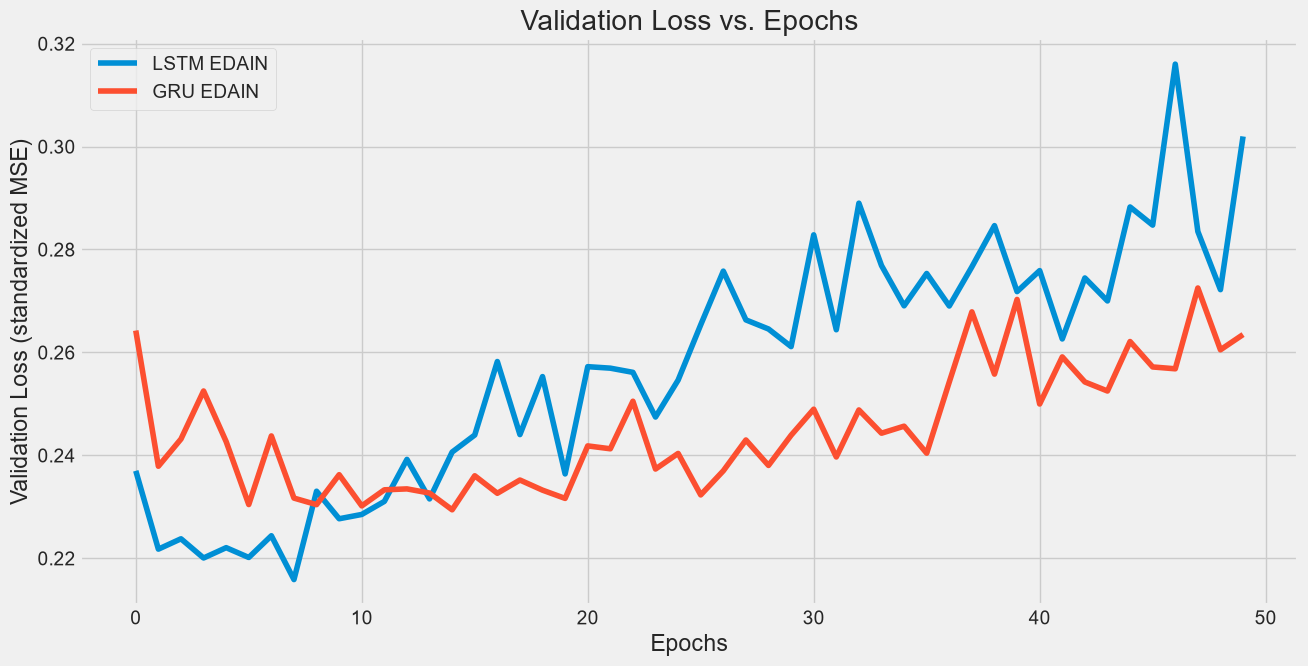

In [21]:
def plot_history(transform, key, title, ylabel):
    plt.figure(figsize=(14, 7))
    for model_type in MODEL_TYPES:
        plt.plot(transform(histories[model_type].history[key]), label=f'{model_type} EDAIN')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()


plot_history(np.asarray, 'loss', 'Training Loss vs. Epochs', 'Loss (standardized MSE)')
plot_history(lambda h: np.log10(h), 'loss', 'Log(Training Loss) vs. Epochs', 'Log10(Loss)')
plot_history(np.asarray, 'val_loss', 'Validation Loss vs. Epochs', 'Validation Loss (standardized MSE)')

### Final Loss

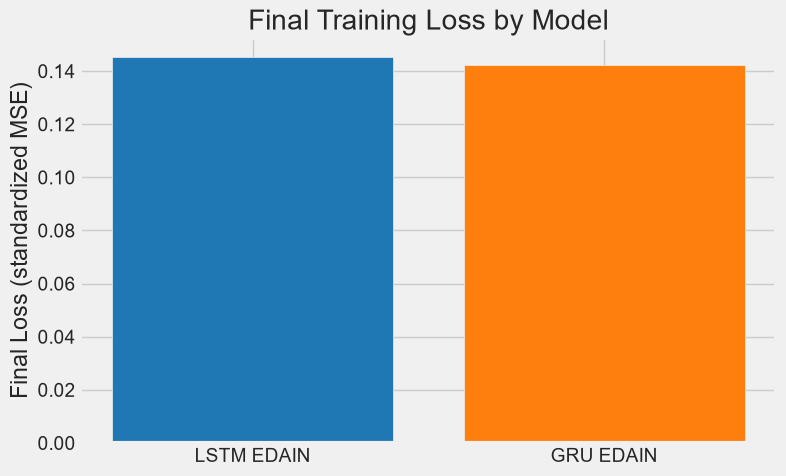

In [22]:
plt.figure(figsize=(8, 5))
plt.bar([f'{m} EDAIN' for m in MODEL_TYPES],
        [histories[m].history['loss'][-1] for m in MODEL_TYPES],
        color=['tab:blue', 'tab:orange'])
plt.title('Final Training Loss by Model')
plt.ylabel('Final Loss (standardized MSE)')
plt.show()

### Metrics Summary

In [24]:
summary = pd.DataFrame(metrics_values).T
summary.index.name = 'Model'
summary.style.format('{:.4f}')

,I-MSE,I-RMSE,I-MAE
Model,,,
LSTM,1.3210,1.1493,0.7990
GRU,1.2457,1.1161,0.7646


## Save results

In [25]:
# Append one row per model to results.csv
import csv
from datetime import datetime
from sklearn.metrics import r2_score

WINDOWS = {m: tuning[m][1] for m in MODEL_TYPES}

def _iverson_r2(actual, prediction):
    """Only needed for the EDAIN notebook, whose metrics table has no R^2."""
    a = np.asarray(actual, dtype=float).reshape(-1)
    p = np.asarray(prediction, dtype=float).reshape(-1)
    mask = a != 0.0
    return float(r2_score(a[mask], p[mask])) if mask.sum() >= 2 else float('nan')


rows = []
for model_name, m in metrics_values.items():
    r2 = m.get('I-R2')
    if r2 is None:                       # EDAIN: computed here, its own table is untouched
        x_test, y_test_raw = test_sets[model_name]
        r2 = _iverson_r2(y_test_raw, predictions[model_name])
    rows.append({
        'run': RUN_NAME,
        'experiment': 4,
        'method': 'EDAIN',
        'backbone': model_name,
        'feature_mode': FEATURE_MODE,
        'target': TARGET_COL,
        'dataset': DATASET,
        'window': WINDOWS[model_name],
        'seed': SEED,
        'I_MSE': round(float(m['I-MSE']), 4),
        'I_RMSE': round(float(m['I-RMSE']), 4),
        'I_MAE': round(float(m['I-MAE']), 4),
        'I_R2': round(float(r2), 4),
        'timestamp': datetime.now().isoformat(timespec='seconds'),
    })

write_header = not os.path.exists(RESULTS_CSV)
with open(RESULTS_CSV, 'a', newline='') as fh:
    writer = csv.DictWriter(fh, fieldnames=list(rows[0]))
    if write_header:
        writer.writeheader()
    writer.writerows(rows)

print(f'Saved {len(rows)} row(s) to {RESULTS_CSV}:')
for r in rows:
    print(f"  {r['backbone']:18s} window={r['window']:3d}  "
          f"I-RMSE={r['I_RMSE']:.4f}  I-MAE={r['I_MAE']:.4f}  I-R2={r['I_R2']:.4f}")


Saved 2 row(s) to results.csv:
  LSTM               window= 30  I-RMSE=1.1493  I-MAE=0.7990  I-R2=-0.4803
  GRU                window= 90  I-RMSE=1.1161  I-MAE=0.7646  I-R2=-0.3724
